# Wetteranalyse: Berlin

In diesem Notebook vergleichen wir historische Tageswerte für Berlin von Open-Meteo mit Stationsmessungen des Deutschen Wetterdienstes (DWD). Untersucht werden Höchst- und Tiefsttemperaturen sowie Niederschlag für die Jahre 2021 bis 2025.

Open-Meteo liefert Werte für Berlin-Mitte (52.52° N, 13.405° E); die DWD-Daten stammen von der Station Berlin-Tempelhof (00433). Da Station und Modellraster nicht am selben Ort liegen, können Abweichungen sowohl aus der Messmethode als auch aus der Lage entstehen.

**Untersuchungszeitraum:** 1. Januar 2021 bis 31. Dezember 2025

## Vorbereitung

Für Tabellen und Diagramme verwenden wir `pandas` und `matplotlib`. Falls diese Pakete in deiner Python-Umgebung fehlen, führe die folgende Zeile in einer Code-Zelle aus:

```python
%pip install pandas matplotlib
```

Die Downloads nutzen Pythons Standardbibliothek; das DWD-ZIP-Archiv wird direkt im Notebook geöffnet.

In [8]:
import json
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd

# Koordinaten von Berlin-Mitte
latitude = 52.52
longitude = 13.405

# Fünf vollständige Kalenderjahre für den Vergleich.
start_date = "2021-01-01"
end_date = "2025-12-31"

## Wetterdaten abrufen

Die Archiv-API liefert tägliche Höchst- und Tiefsttemperaturen sowie die Niederschlagssumme. Wenn du `start_date` und `end_date` oben änderst, kannst du einen anderen Zeitraum abrufen. Die API hat nur Daten für vergangene Tage; die Internetverbindung muss beim Ausführen verfügbar sein.

In [9]:
parameter = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
    "timezone": "Europe/Berlin",
}
api_url = "https://archive-api.open-meteo.com/v1/archive"
url = f"{api_url}?{urlencode(parameter)}"

with urlopen(url, timeout=30) as antwort:
    wetter_roh = json.load(antwort)

print("Einheiten:", wetter_roh["daily_units"])
print("Anzahl der Tage:", len(wetter_roh["daily"]["time"]))

Einheiten: {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}
Anzahl der Tage: 1826


## Vergleichsdaten vom DWD laden

Zusätzlich laden wir die offiziellen Tagesdaten der DWD-Station **Berlin-Tempelhof (00433)**. Das Archiv enthält Höchst-, Tiefst- und Mitteltemperatur sowie Niederschlag. Die DWD-CSV ist in einem ZIP-Archiv gespeichert; `zipfile` und `pandas` lesen sie direkt ein, ohne dass eine Datei manuell heruntergeladen werden muss.

In [16]:
import io
import zipfile

# DWD-Tagesdaten der Station Berlin-Tempelhof (Stations-ID 00433).
dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/"
    "climate/daily/kl/historical/"
    "tageswerte_KL_00433_19480101_20251231_hist.zip"
)
with urlopen(dwd_url, timeout=60) as antwort:
    dwd_zip_daten = antwort.read()

with zipfile.ZipFile(io.BytesIO(dwd_zip_daten)) as archiv:
    produktdatei = next(
        name
        for name in archiv.namelist()
        if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
    )
    with archiv.open(produktdatei) as csv_datei:
        dwd_roh = pd.read_csv(
            csv_datei,
            sep=";",
            skipinitialspace=True,
            na_values=[-999, "-999"],
            low_memory=False,
        )

dwd_roh.columns = dwd_roh.columns.str.strip()
dwd_wetter = dwd_roh[["MESS_DATUM", "TXK", "TNK", "TMK", "RSK"]].copy()
dwd_wetter["datum"] = pd.to_datetime(
    dwd_wetter["MESS_DATUM"].astype("Int64").astype(str),
    format="%Y%m%d",
)
for spalte in ["TXK", "TNK", "TMK", "RSK"]:
    dwd_wetter[spalte] = pd.to_numeric(dwd_wetter[spalte], errors="coerce")

dwd_wetter = dwd_wetter.loc[
    dwd_wetter["datum"].between(start_date, end_date),
    ["datum", "TXK", "TNK", "TMK", "RSK"],
].rename(
    columns={
        "TXK": "temp_max_dwd",
        "TNK": "temp_min_dwd",
        "TMK": "temp_mittel_dwd",
        "RSK": "niederschlag_dwd_mm",
    }
).reset_index(drop=True)

print(f"DWD-Station: Berlin-Tempelhof (00433), {len(dwd_wetter)} Tage")
print("Fehlende DWD-Werte:\n", dwd_wetter.isna().sum())
dwd_wetter.head()

DWD-Station: Berlin-Tempelhof (00433), 1826 Tage
Fehlende DWD-Werte:
 datum                   0
temp_max_dwd            0
temp_min_dwd            0
temp_mittel_dwd         0
niederschlag_dwd_mm    10
dtype: int64


,datum,temp_max_dwd,temp_min_dwd,temp_mittel_dwd,niederschlag_dwd_mm
0,2021-01-01,3.0,0.6,2.1,1.0
1,2021-01-02,4.2,-0.9,1.1,0.0
2,2021-01-03,1.1,-0.3,0.6,6.0
3,2021-01-04,0.9,0.6,0.8,0.3
4,2021-01-05,3.5,0.7,1.7,1.6


## Daten als Tabellen

Open-Meteo und DWD werden zunächst in getrennten Tabellen gespeichert. Jede Zeile steht für einen Tag; die Spalten enthalten Datum, Temperatur und Niederschlag. Danach gleichen wir die Datumswerte ab, damit nur gemeinsame Tage verglichen werden.

In [10]:
wetter = pd.DataFrame(
    {
        "datum": pd.to_datetime(wetter_roh["daily"]["time"]),
        "temp_max": wetter_roh["daily"]["temperature_2m_max"],
        "temp_min": wetter_roh["daily"]["temperature_2m_min"],
        "niederschlag_mm": wetter_roh["daily"]["precipitation_sum"],
    }
)

wetter.head()

,datum,temp_max,temp_min,niederschlag_mm
0,2021-01-01,2.1,-0.8,0.7
1,2021-01-02,2.6,-1.1,0.0
2,2021-01-03,0.8,-1.1,11.0
3,2021-01-04,1.2,-0.4,3.6
4,2021-01-05,2.8,0.1,0.6


## Abweichungen für gemeinsame Tage

Wir verbinden die Quellen über das Datum und berechnen die mittlere absolute Abweichung. Für Niederschlag werden nur Tage berücksichtigt, an denen beide Quellen einen Wert haben.

In [22]:
tagesvergleich = wetter[
    ["datum", "temp_max", "temp_min", "niederschlag_mm"]
].merge(
    dwd_wetter[
        [
            "datum",
            "temp_max_dwd",
            "temp_min_dwd",
            "temp_mittel_dwd",
            "niederschlag_dwd_mm",
        ]
    ],
    on="datum",
    how="inner",
    validate="one_to_one",
)
gemeinsame_niederschlagstage = tagesvergleich[
    ["niederschlag_mm", "niederschlag_dwd_mm"]
].dropna()

print(f"Gemeinsame Tage: {len(tagesvergleich)}")
print(
    "Mittlere absolute Abweichung Tageshöchsttemperatur: "
    f"{tagesvergleich['temp_max'].sub(tagesvergleich['temp_max_dwd']).abs().mean():.2f} °C"
)
print(
    "Mittlere absolute Abweichung Tagestiefsttemperatur: "
    f"{tagesvergleich['temp_min'].sub(tagesvergleich['temp_min_dwd']).abs().mean():.2f} °C"
)
print(f"Tage mit beiden Niederschlagswerten: {len(gemeinsame_niederschlagstage)}")
print(
    "Mittlere absolute Abweichung Niederschlag: "
    f"{gemeinsame_niederschlagstage['niederschlag_mm'].sub(gemeinsame_niederschlagstage['niederschlag_dwd_mm']).abs().mean():.2f} mm"
)
tagesvergleich.head()

Gemeinsame Tage: 1826
Mittlere absolute Abweichung Tageshöchsttemperatur: 1.02 °C
Mittlere absolute Abweichung Tagestiefsttemperatur: 0.84 °C
Tage mit beiden Niederschlagswerten: 1816
Mittlere absolute Abweichung Niederschlag: 1.25 mm


,datum,temp_max,temp_min,niederschlag_mm,temp_max_dwd,temp_min_dwd,temp_mittel_dwd,niederschlag_dwd_mm
0,2021-01-01,2.1,-0.8,0.7,3.0,0.6,2.1,1.0
1,2021-01-02,2.6,-1.1,0.0,4.2,-0.9,1.1,0.0
2,2021-01-03,0.8,-1.1,11.0,1.1,-0.3,0.6,6.0
3,2021-01-04,1.2,-0.4,3.6,0.9,0.6,0.8,0.3
4,2021-01-05,2.8,0.1,0.6,3.5,0.7,1.7,1.6


## Kennzahlen pro Jahr

Die Tabelle stellt Open-Meteo und DWD nebeneinander. Sie vergleicht mittlere Tageshöchst- und Tiefsttemperaturen, Niederschlagssummen sowie Frost- und Sommertage. Die Spalte mit der Anzahl gültiger Niederschlagswerte macht Datenlücken sichtbar.

In [17]:
wetter["jahr"] = wetter["datum"].dt.year
dwd_wetter["jahr"] = dwd_wetter["datum"].dt.year

jahreswerte_open_meteo = wetter.groupby("jahr").agg(
    mittlere_hoechsttemperatur_c=("temp_max", "mean"),
    mittlere_tiefsttemperatur_c=("temp_min", "mean"),
    niederschlag_mm=("niederschlag_mm", "sum"),
    frosttage=("temp_min", lambda werte: (werte < 0).sum()),
    sommertage=("temp_max", lambda werte: (werte >= 25).sum()),
    tage_mit_niederschlagswert=("niederschlag_mm", "count"),
)
jahreswerte_dwd = dwd_wetter.groupby("jahr").agg(
    mittlere_hoechsttemperatur_c=("temp_max_dwd", "mean"),
    mittlere_tiefsttemperatur_c=("temp_min_dwd", "mean"),
    niederschlag_mm=("niederschlag_dwd_mm", "sum"),
    frosttage=("temp_min_dwd", lambda werte: (werte < 0).sum()),
    sommertage=("temp_max_dwd", lambda werte: (werte >= 25).sum()),
    tage_mit_niederschlagswert=("niederschlag_dwd_mm", "count"),
)

jahresvergleich = pd.concat(
    {
        "Open-Meteo": jahreswerte_open_meteo,
        "DWD Tempelhof": jahreswerte_dwd,
    },
    axis=1,
)
jahresvergleich.round(1)

Open-Meteo                                              \
     mittlere_hoechsttemperatur_c mittlere_tiefsttemperatur_c niederschlag_mm   
jahr                                                                            
2021                         13.6                         5.9           661.1   
2022                         15.2                         6.6           489.0   
2023                         15.0                         7.1           830.9   
2024                         15.7                         7.7           647.3   
2025                         14.7                         6.7           610.5   

                                                      \
     frosttage sommertage tage_mit_niederschlagswert   
jahr                                                   
2021        88         41                        365   
2022        69         54                        365   
2023        63         59                        365   
2024        44         60                        366   
2025        65         38                        365   

                    DWD Tempelhof                                              \
     mittlere_hoechsttemperatur_c mittlere_tiefsttemperatur_c niederschlag_mm   
jahr                                                                            
2021                         14.5                         6.5           532.4   
2022                         16.0                         7.1           389.3   
2023                         15.7                         7.2           744.0   
2024                         16.5                         7.8           553.3   
2025                         15.6                         6.5           458.5   

                                                      
     frosttage sommertage tage_mit_niederschlagswert  
jahr                                                  
2021        64         56                        365  
2022        54         68                        365  
2023        51         69                        355  
2024        41         74                        366  
2025        60         51                        365

In [20]:
open_meteo_monate = wetter.assign(
    jahr=wetter["datum"].dt.year,
    monat=wetter["datum"].dt.month,
).groupby(["jahr", "monat"]).agg(
    temp_max_mittel=("temp_max", "mean"),
    niederschlag_mm=("niederschlag_mm", "sum"),
)
dwd_monate = dwd_wetter.assign(
    jahr=dwd_wetter["datum"].dt.year,
    monat=dwd_wetter["datum"].dt.month,
).groupby(["jahr", "monat"]).agg(
    temp_max_mittel=("temp_max_dwd", "mean"),
    niederschlag_mm=("niederschlag_dwd_mm", "sum"),
)

monatswerte_quellen = {
    "Open-Meteo": open_meteo_monate,
    "DWD Tempelhof": dwd_monate,
}
monatswerte_quellen["DWD Tempelhof"].round(1)

temp_max_mittel  niederschlag_mm
jahr monat                                  
2021 1                  3.3             45.1
     2                  5.2             27.6
     3                 10.5             31.8
     4                 12.0             21.2
     5                 17.2             53.7
     6                 27.3             55.0
     7                 26.0             53.4
     8                 22.9             76.1
     9                 20.8             35.3
     10                15.5             20.3
     11                 8.7             67.5
     12                 4.4             45.4
2022 1                  5.7             29.6
     2                  8.6             55.0
     3                 11.5              1.3
     4                 13.7             29.1
     5                 21.2             31.0
     6                 26.8             22.0
     7                 26.3             33.0
     8                 27.8             58.5
     9                 19.0             47.4
     10                18.0             23.3
     11                 9.1              9.2
     12                 4.0             49.9
2023 1                  6.8             65.2
     2                  6.9             43.4
     3                 10.1             69.4
     4                 12.8             47.5
     5                 20.0             14.1
     6                 25.5             77.2
     7                 26.0             74.1
     8                 24.6             57.2
     9                 25.1             21.6
     10                15.9             93.2
     11                 8.7             64.4
     12                 6.0            116.7
2024 1                  4.6             45.7
     2                 10.2             71.2
     3                 13.1             35.3
     4                 16.7             26.0
     5                 23.2             34.5
     6                 23.9             48.5
     7                 25.9            102.4
     8                 27.4             31.6
     9                 23.3             41.4
     10                15.8             26.6
     11                 8.0             53.7
     12                 6.0             36.4
2025 1                  5.6             54.9
     2                  5.4             16.0
     3                 12.7              8.7
     4                 18.0             13.7
     5                 19.3             33.8
     6                 25.8             34.6
     7                 24.7            127.4
     8                 24.8             32.6
     9                 21.5             35.1
     10                13.9             44.8
     11                 9.0             37.2
     12                 6.2             19.7

## Täglicher Verlauf von Open-Meteo

Das Diagramm zeigt die Tageshöchst- und Tiefsttemperaturen sowie den Niederschlag aus Open-Meteo über den gesamten Zeitraum. Der direkte Quellenvergleich folgt in der Jahresübersicht und den Monatsdiagrammen.

Gespeichert: berlin_tageswerte_2021-01-01_2025-12-31.png


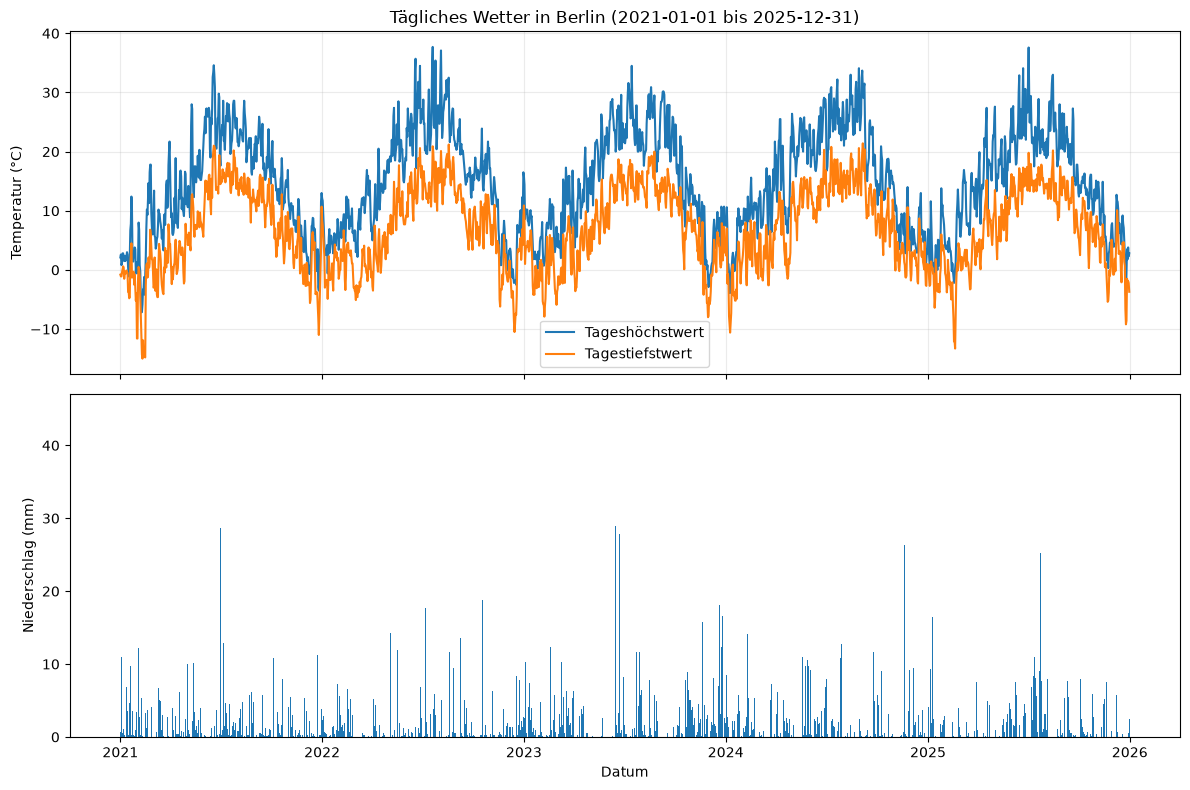

In [13]:
fig, achsen = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

achsen[0].plot(wetter["datum"], wetter["temp_max"], label="Tageshöchstwert")
achsen[0].plot(wetter["datum"], wetter["temp_min"], label="Tagestiefstwert")
achsen[0].set_ylabel("Temperatur (°C)")
achsen[0].set_title(f"Tägliches Wetter in Berlin ({start_date} bis {end_date})")
achsen[0].legend()
achsen[0].grid(alpha=0.25)

achsen[1].bar(wetter["datum"], wetter["niederschlag_mm"], width=1.0)
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].set_xlabel("Datum")

fig.tight_layout()
dateiname_tageswerte = f"berlin_tageswerte_{start_date}_{end_date}.png"
fig.savefig(dateiname_tageswerte, dpi=150, bbox_inches="tight")
print(f"Gespeichert: {dateiname_tageswerte}")
plt.show()

## Monate und Quellen vergleichen

Die vier Diagramme zeigen Open-Meteo und DWD nebeneinander: oben die mittlere Tageshöchsttemperatur je Monat, unten die Niederschlagssumme. Die Farben stehen in allen Diagrammen für dieselben Jahre.

Gespeichert: berlin_dwd_openmeteo_monatsvergleich_2021-2025.png


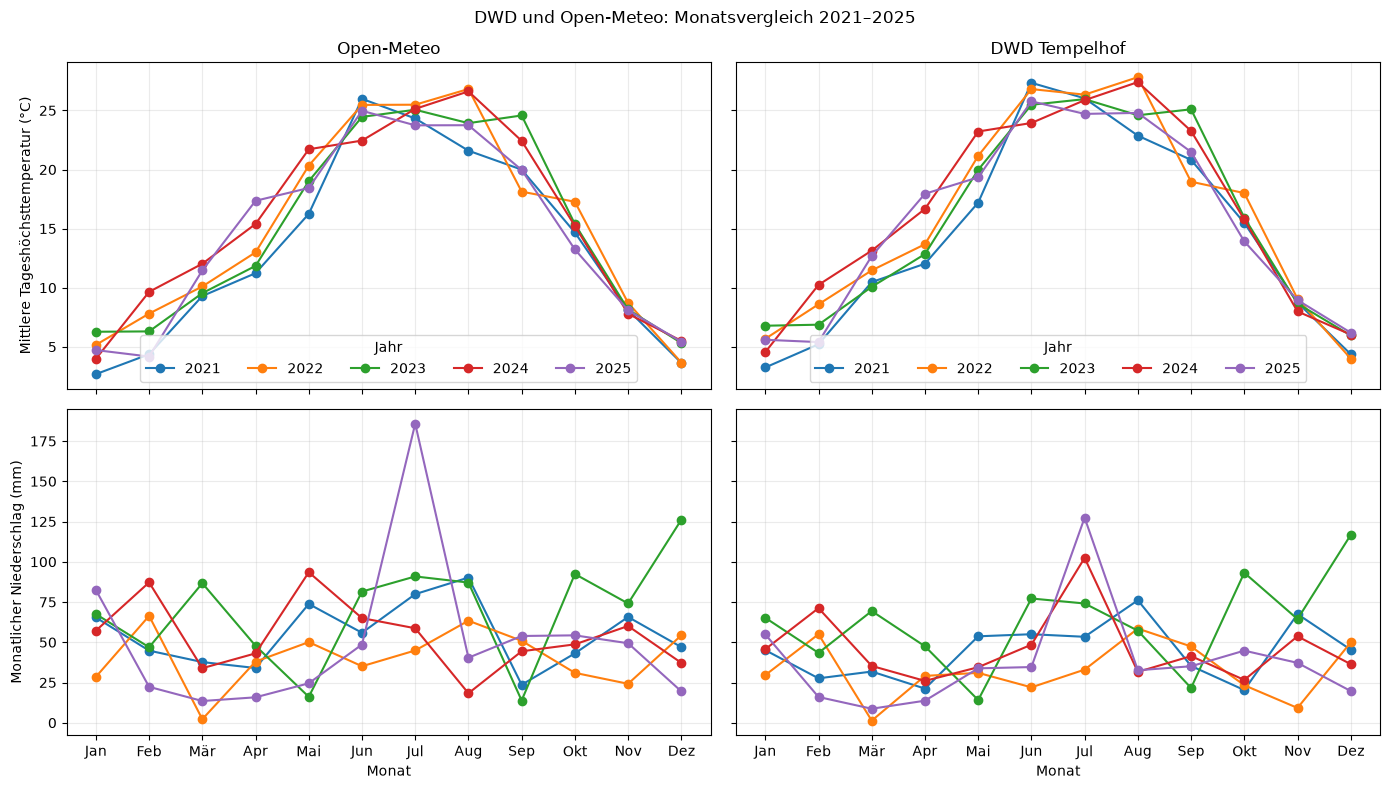

In [21]:
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
fig, achsen = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey="row")

for spalte, (quelle, monatswerte) in enumerate(monatswerte_quellen.items()):
    for jahr, werte in monatswerte.groupby(level="jahr"):
        monate = werte.index.get_level_values("monat")
        achsen[0, spalte].plot(
            monate,
            werte["temp_max_mittel"],
            marker="o",
            label=str(jahr),
        )
        achsen[1, spalte].plot(
            monate,
            werte["niederschlag_mm"],
            marker="o",
        )

    achsen[0, spalte].set_title(quelle)
    achsen[0, spalte].legend(title="Jahr", ncols=5)
    achsen[0, spalte].grid(alpha=0.25)
    achsen[1, spalte].set_xticks(range(1, 13), monatsnamen)
    achsen[1, spalte].grid(alpha=0.25)

achsen[0, 0].set_ylabel("Mittlere Tageshöchsttemperatur (°C)")
achsen[1, 0].set_ylabel("Monatlicher Niederschlag (mm)")
achsen[1, 0].set_xlabel("Monat")
achsen[1, 1].set_xlabel("Monat")

fig.suptitle(f"DWD und Open-Meteo: Monatsvergleich {start_date[:4]}–{end_date[:4]}")
fig.tight_layout()
dateiname_monate = f"berlin_dwd_openmeteo_monatsvergleich_{start_date[:4]}-{end_date[:4]}.png"
fig.savefig(dateiname_monate, dpi=150, bbox_inches="tight")
print(f"Gespeichert: {dateiname_monate}")
plt.show()

## Einordnung und eigene Fragen

Open-Meteo stellt historische Modell- bzw. Reanalysedaten für Berlin-Mitte bereit. Der DWD liefert Stationsmessungen aus Berlin-Tempelhof (00433). Die Orte liegen einige Kilometer auseinander; Abweichungen können daher sowohl an der Quelle als auch am Standort liegen. Die DWD-Daten stammen aus dem [DWD-CDC-Archiv für tägliche Klimadaten](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/historical/). Weitere Informationen zu Open-Meteo stehen in der [Dokumentation](https://open-meteo.com/en/docs/historical-weather-api).

Im DWD-Archiv fehlen im betrachteten Zeitraum zehn tägliche Niederschlagswerte. Summen und mittlere Abweichung berücksichtigen deshalb nur vorhandene Werte; die Tabellen zeigen die Anzahl gültiger Niederschlagsmessungen.

Zum Weiterforschen:

- Welcher Anbieter meldet im Jahresmittel höhere Tageshöchsttemperaturen?
- In welchem Jahr war der Niederschlag je Quelle am höchsten?
- Ändere den Zeitraum und führe danach alle Zellen von oben nach unten erneut aus.

Die PNG-Dateien werden im aktuellen Notebook-Arbeitsordner abgelegt. Das Tagesdiagramm enthält Start- und Enddatum im Dateinamen; die Monatsgrafik enthält die verglichenen Jahre.